# FOV-Aware KUB Object-Size Taxonomy
This live report runs the reconciled Phase 7-R1 pipeline from frozen `phase4_v2` manifests. Thresholds use TRAIN FULL_FIELD components only; TEST masks and external data are not accessed.

In [1]:
import sys, pandas as pd
from pathlib import Path
from IPython.display import Image, display
ROOT = Path(r'D:\Softfors\jup')
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.utils.manifest_guard import verify_manifests
from src.analysis.kub_object_size import load_phase7_artifacts, validate_phase7_artifacts
T=ROOT/'reports'/'tables'; A=ROOT/'reports'/'audits'
verify_manifests()
artifacts=load_phase7_artifacts(ROOT)
assert validate_phase7_artifacts(artifacts)
ss=artifacts['fov_samples']; cs=artifacts['fov_components']
sc=artifacts['fov_sample_category']; cc=artifacts['fov_component_category']
sz=artifacts['category_size']; tv=artifacts['train_val_size']
print('Manifest guard and source-of-truth assertions: PASS')
print('TEST mask reads:', int(artifacts['provenance']['test_mask_reads']))

Manifests verified successfully.
Manifest guard and source-of-truth assertions: PASS
TEST mask reads: 0


## Reconciled sample-level and component-level FOV tables

In [2]:
display(ss); display(sc); display(cs); display(cc)
display(pd.read_csv(T/'kub_fov_characteristics_v2.csv'))
display(pd.read_csv(T/'kub_fov_patient_summary_v2.csv'))

,split,view_type,samples,patients,percent
0,TRAIN,FULL_FIELD,771,316,38.95907
1,TRAIN,ROI_CROP,1208,318,61.04093
2,TRAIN,UNRESOLVED,0,0,0.00000
3,VAL,FULL_FIELD,106,106,37.45583
4,VAL,ROI_CROP,177,111,62.54417
5,VAL,UNRESOLVED,0,0,0.00000


,category,full_field,roi_crop,unresolved,total_samples
0,Kidney_Stone,421,712,0,1133
1,Bladder_Stone,253,382,0,635
2,Ureteric_Stone,97,114,0,211


,split,view_type,components,samples,median_component_ratio
0,TRAIN,FULL_FIELD,1162,771,0.000340
1,TRAIN,ROI_CROP,1214,1208,0.300635
2,TRAIN,UNRESOLVED,0,0,NaN
3,VAL,FULL_FIELD,156,106,0.000178
4,VAL,ROI_CROP,177,177,0.258766
5,VAL,UNRESOLVED,0,0,NaN


,category,full_field,roi_crop,unresolved,total_components
0,Kidney_Stone,709,717,0,1426
1,Bladder_Stone,344,383,0,727
2,Ureteric_Stone,109,114,0,223


,view_type,unit,metric,min,q1,median,mean,q3,max
0,FULL_FIELD,sample,width,1.476000e+03,2.304000e+03,2.304000e+03,2.437816e+03,2.304000e+03,3.096000e+03
1,FULL_FIELD,sample,height,2.520000e+03,2.880000e+03,2.880000e+03,2.973516e+03,2.880000e+03,3.528000e+03
2,FULL_FIELD,sample,image_area,4.799952e+06,6.635520e+06,6.635520e+06,7.285076e+06,6.635520e+06,1.066867e+07
3,FULL_FIELD,sample,foreground_pixels,2.590000e+02,1.420000e+03,3.017000e+03,1.047627e+04,8.282500e+03,3.791340e+05
4,FULL_FIELD,sample,foreground_ratio,2.744463e-05,1.920724e-04,4.424672e-04,1.446972e-03,1.240219e-03,4.086930e-02
5,FULL_FIELD,component,component_ratio,2.744463e-05,1.499767e-04,3.397647e-04,9.600822e-04,8.266496e-04,1.703589e-02
6,ROI_CROP,sample,width,4.700000e+01,6.900000e+01,8.500000e+01,1.074768e+02,1.190000e+02,4.950000e+02
7,ROI_CROP,sample,height,4.900000e+01,7.000000e+01,9.100000e+01,1.176656e+02,1.310000e+02,6.680000e+02
8,ROI_CROP,sample,image_area,2.448000e+03,4.890000e+03,7.781000e+03,1.712560e+04,1.482100e+04,2.952560e+05
9,ROI_CROP,sample,foreground_pixels,2.710000e+02,1.141750e+03,2.330000e+03,6.849376e+03,5.715000e+03,1.313130e+05


,group,patients
0,FULL_FIELD,316
1,ROI_CROP,318
2,BOTH,316
3,UNION,318


## Frozen taxonomy, subgroup counts, patients, and validation transfer

In [3]:
display(artifacts['thresholds'])
display(sz); display(tv)
display(artifacts['patients_per_stratum'])
display(artifacts['patient_summary'])
mc=artifacts['multicomponent']
multi_n=len(mc); mixed_n=int(mc.mixed_strata.sum()); tiny_larger=int(mc.tiny_plus_larger.sum())
display(pd.DataFrame({'metric':['FULL_FIELD images','Multi-component images','Multi-component % of FULL_FIELD','Mixed-stratum images','Mixed % among multi-component','Mixed % among all FULL_FIELD','TINY + larger'],'value':[771,multi_n,100*multi_n/771,mixed_n,100*mixed_n/multi_n,100*mixed_n/771,tiny_larger]}))

,boundary,value,definition
0,Q25,0.000150,TINY: ratio <= Q25
1,Q50,0.000340,SMALL: Q25 < ratio <= Q50
2,Q75,0.000827,MEDIUM: Q50 < ratio <= Q75; LARGE: ratio > Q75


,category,TINY,SMALL,MEDIUM,LARGE,TOTAL
0,Kidney_Stone,48,173,212,276,709
1,Bladder_Stone,221,85,31,7,344
2,Ureteric_Stone,22,32,47,8,109


,stratum,components,percent,split
0,TINY,291,25.043029,TRAIN
1,SMALL,290,24.956971,TRAIN
2,MEDIUM,290,24.956971,TRAIN
3,LARGE,291,25.043029,TRAIN
4,TINY,73,46.794872,VAL
5,SMALL,29,18.589744,VAL
6,MEDIUM,36,23.076923,VAL
7,LARGE,18,11.538462,VAL


,stratum,patients
0,TINY,128
1,SMALL,141
2,MEDIUM,127
3,LARGE,89


,metric,value
0,full_field_patients,316
1,exactly_1_stratum,183
2,exactly_2_strata,100
3,exactly_3_strata,30
4,all_4_strata,3
5,at_least_2_strata,133


,metric,value
0,FULL_FIELD images,771.000000
1,Multi-component images,206.000000
2,Multi-component % of FULL_FIELD,26.718547
3,Mixed-stratum images,135.000000
4,Mixed % among multi-component,65.533981
5,Mixed % among all FULL_FIELD,17.509728
6,TINY + larger,44.000000


## Publication figures

kub_fov_composition_v2


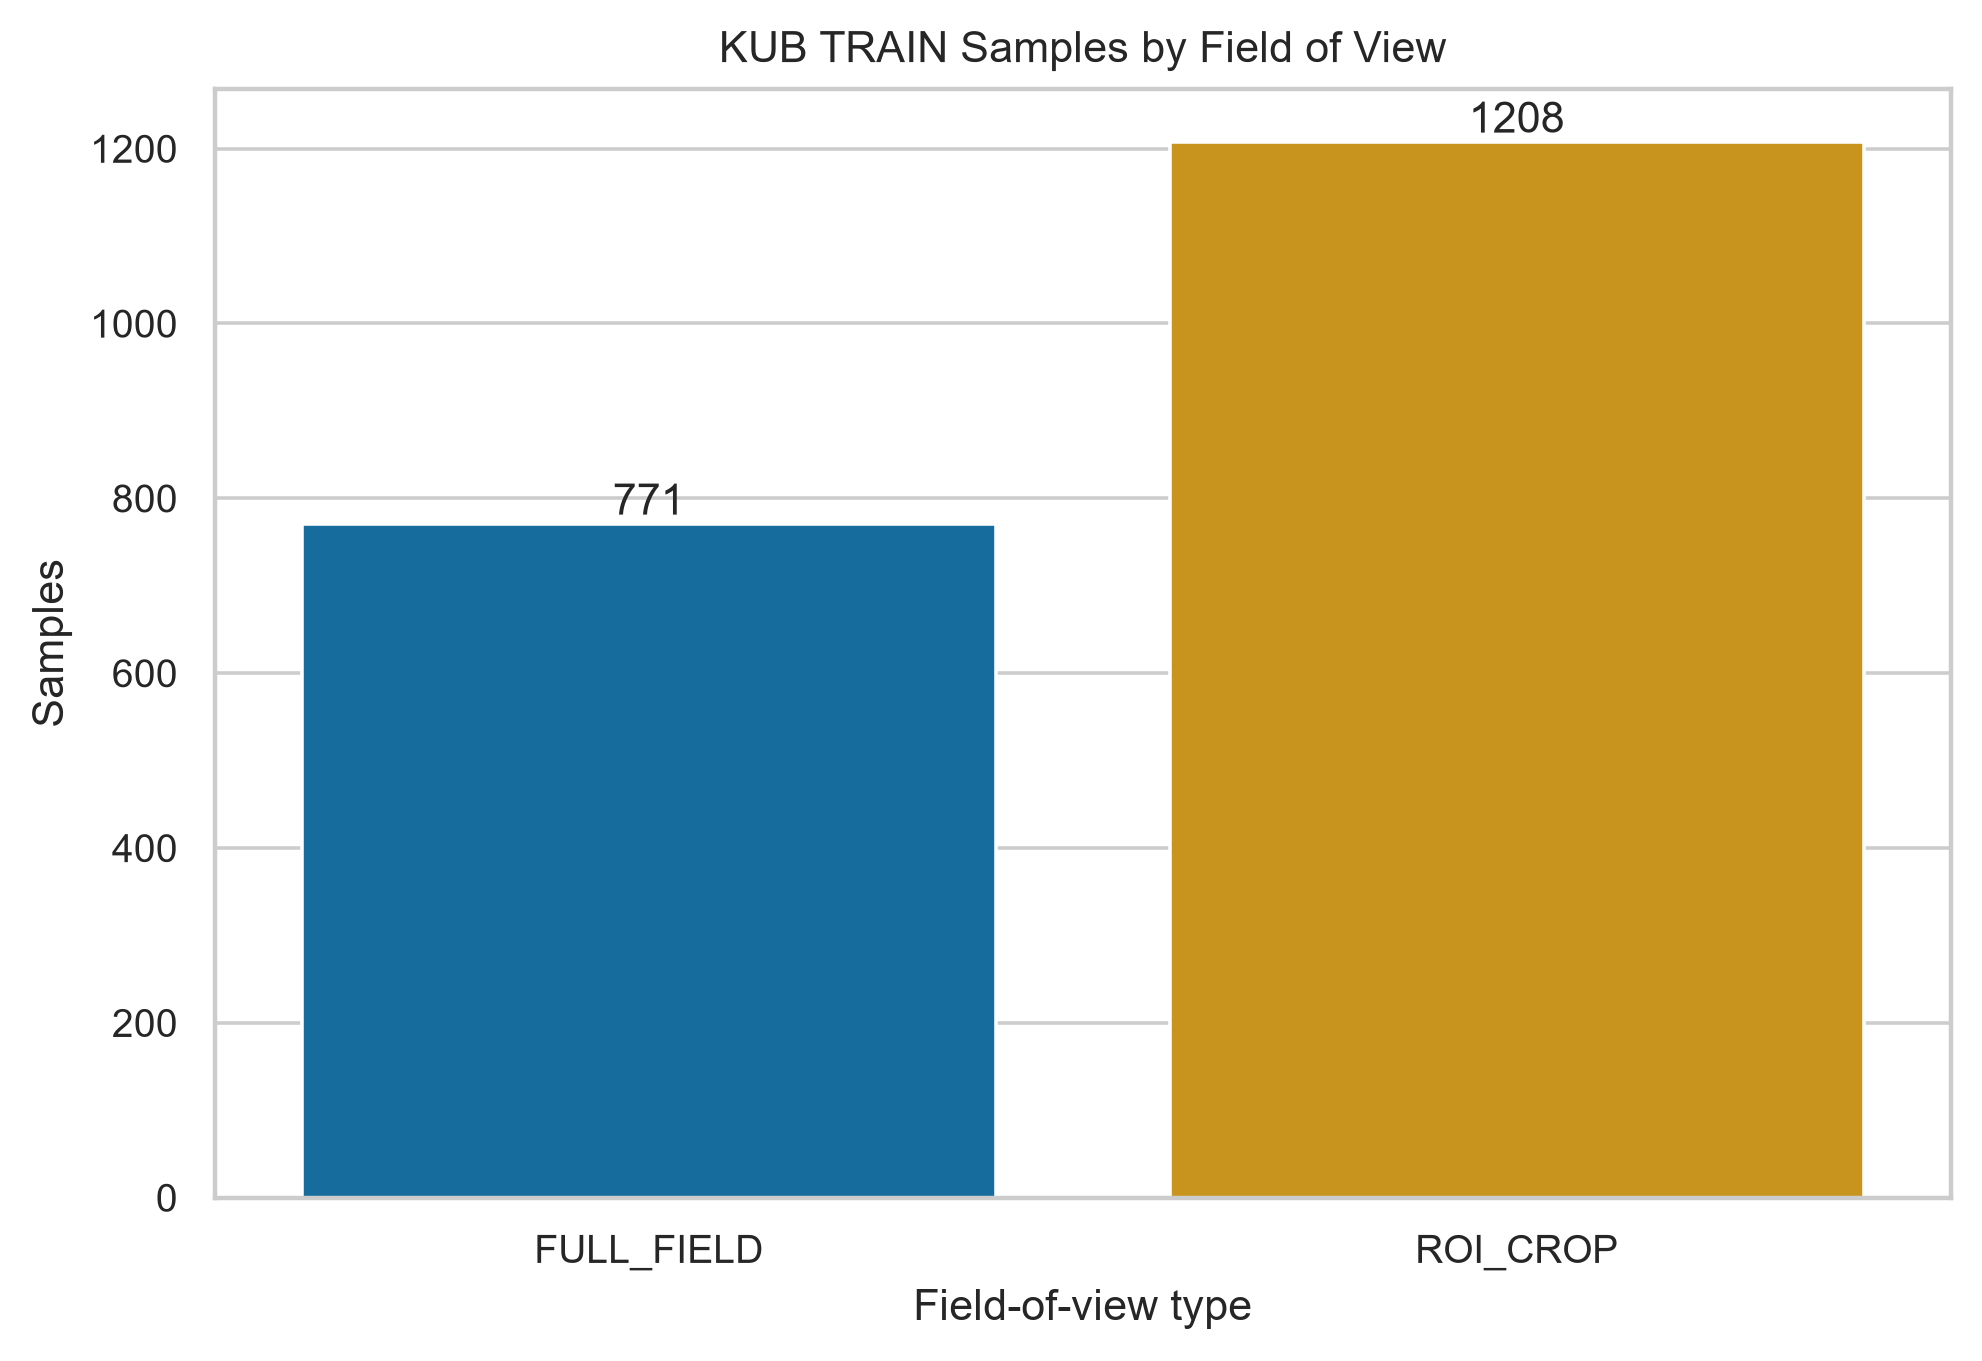

kub_fov_dimension_distribution_v2


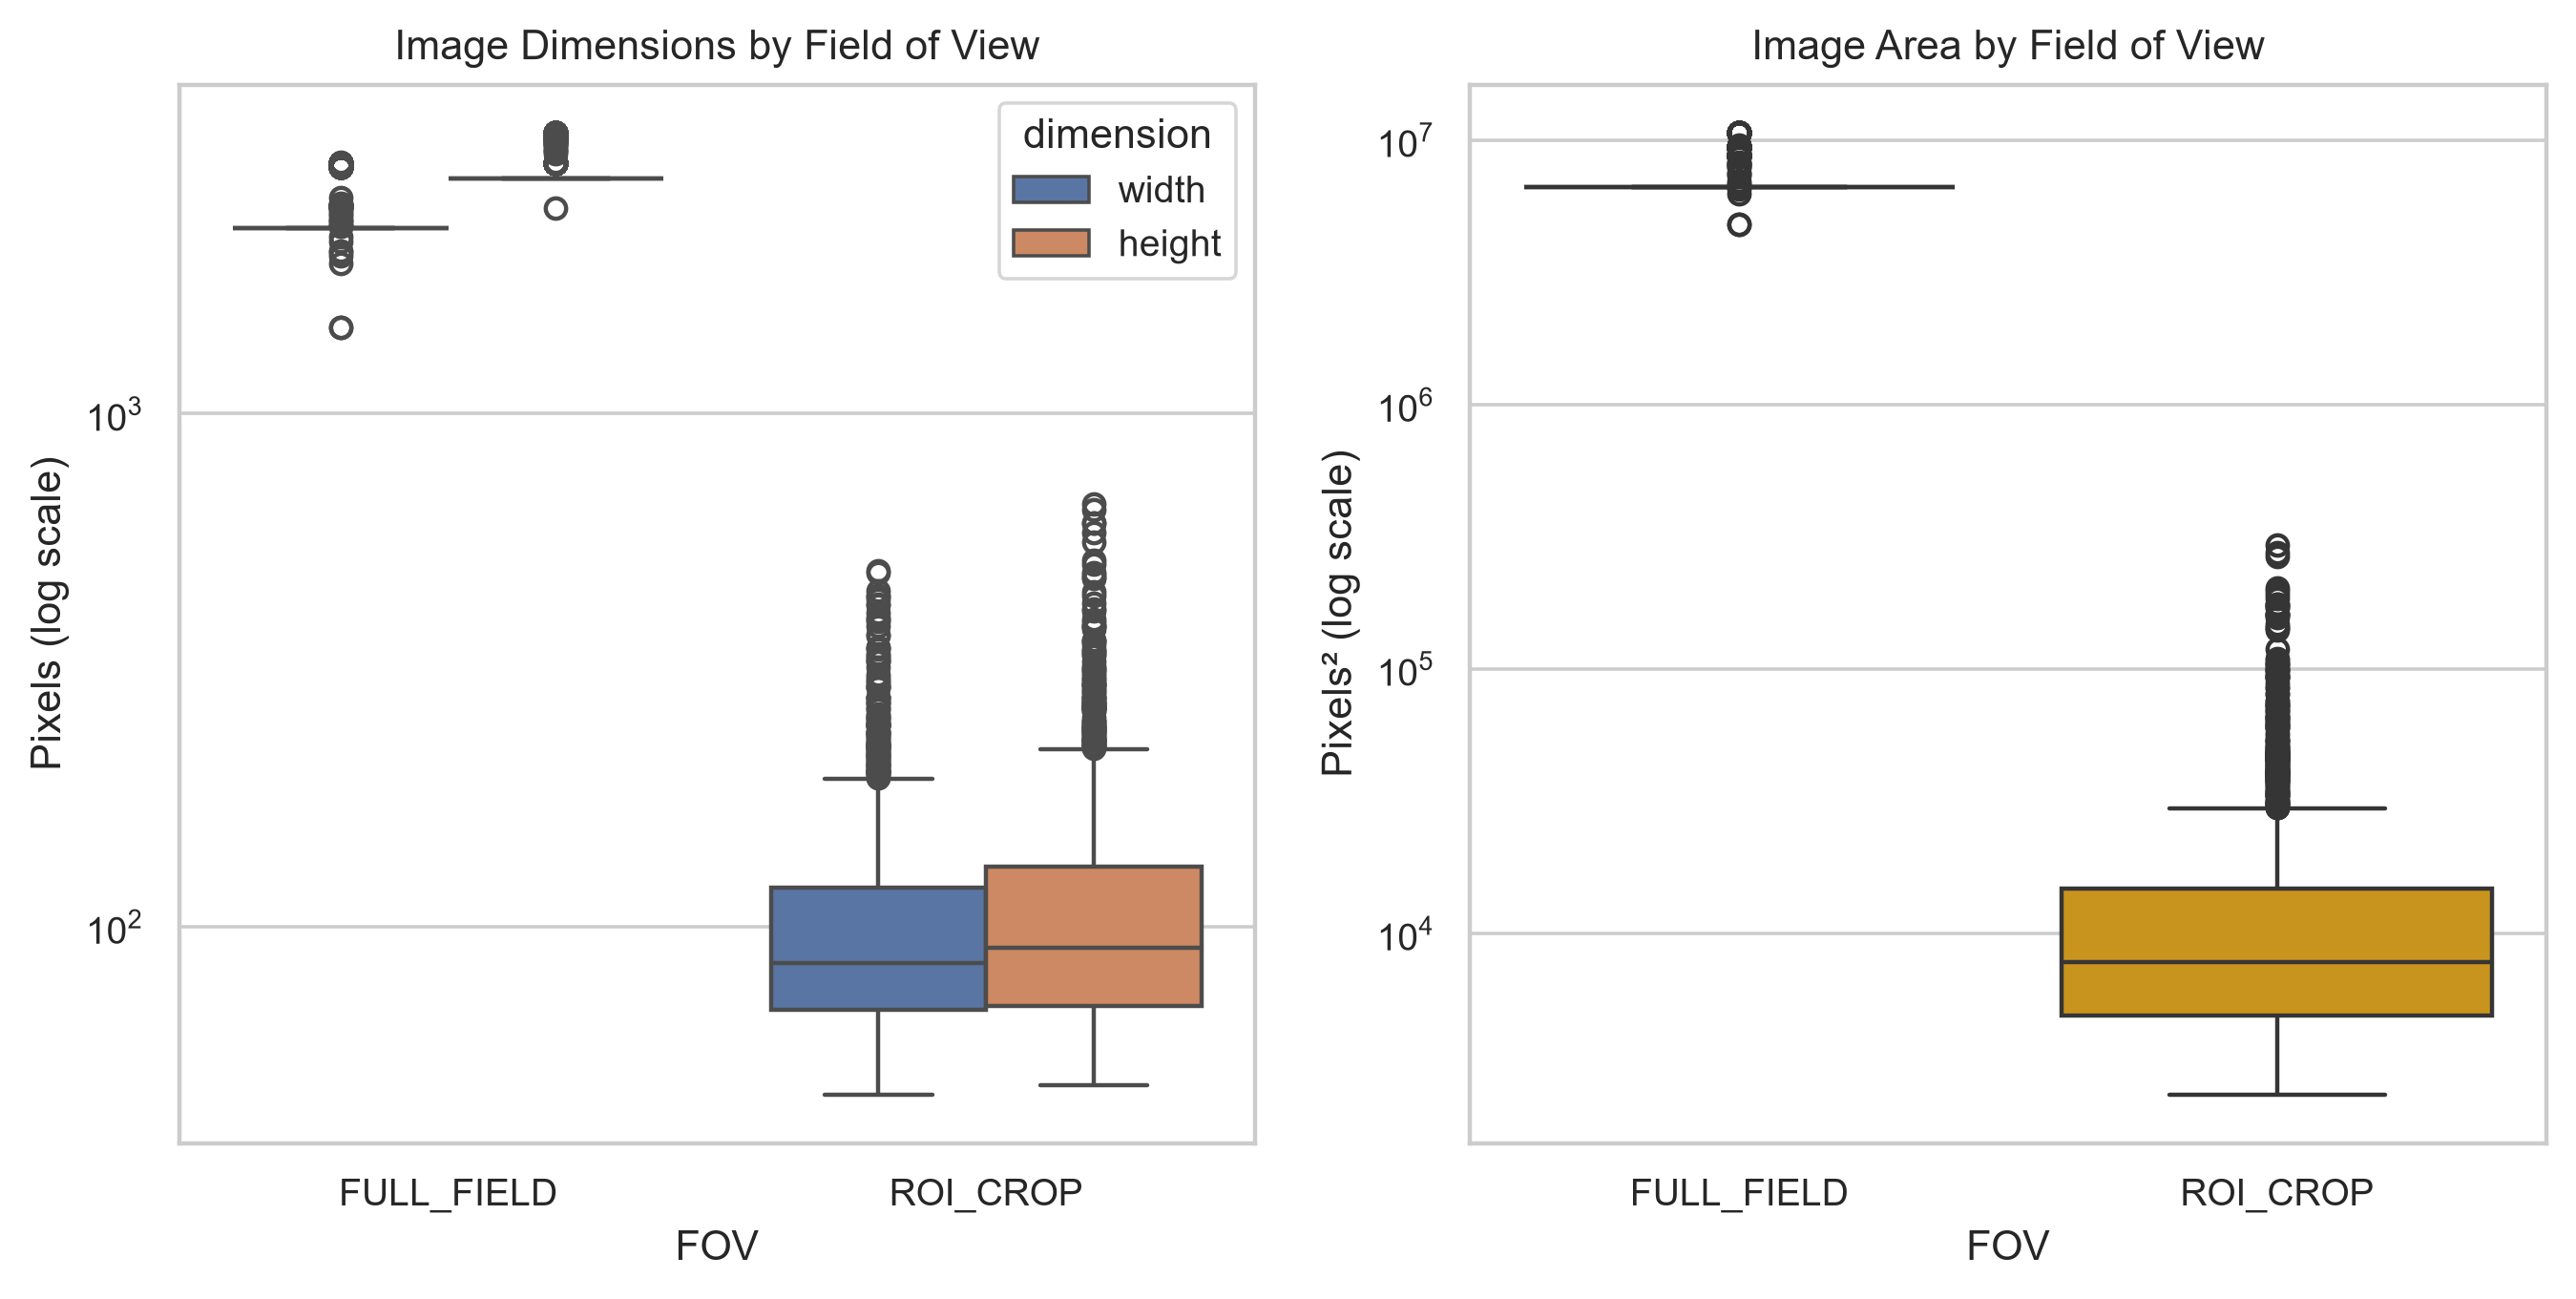

kub_fullfield_object_size_thresholds_v2


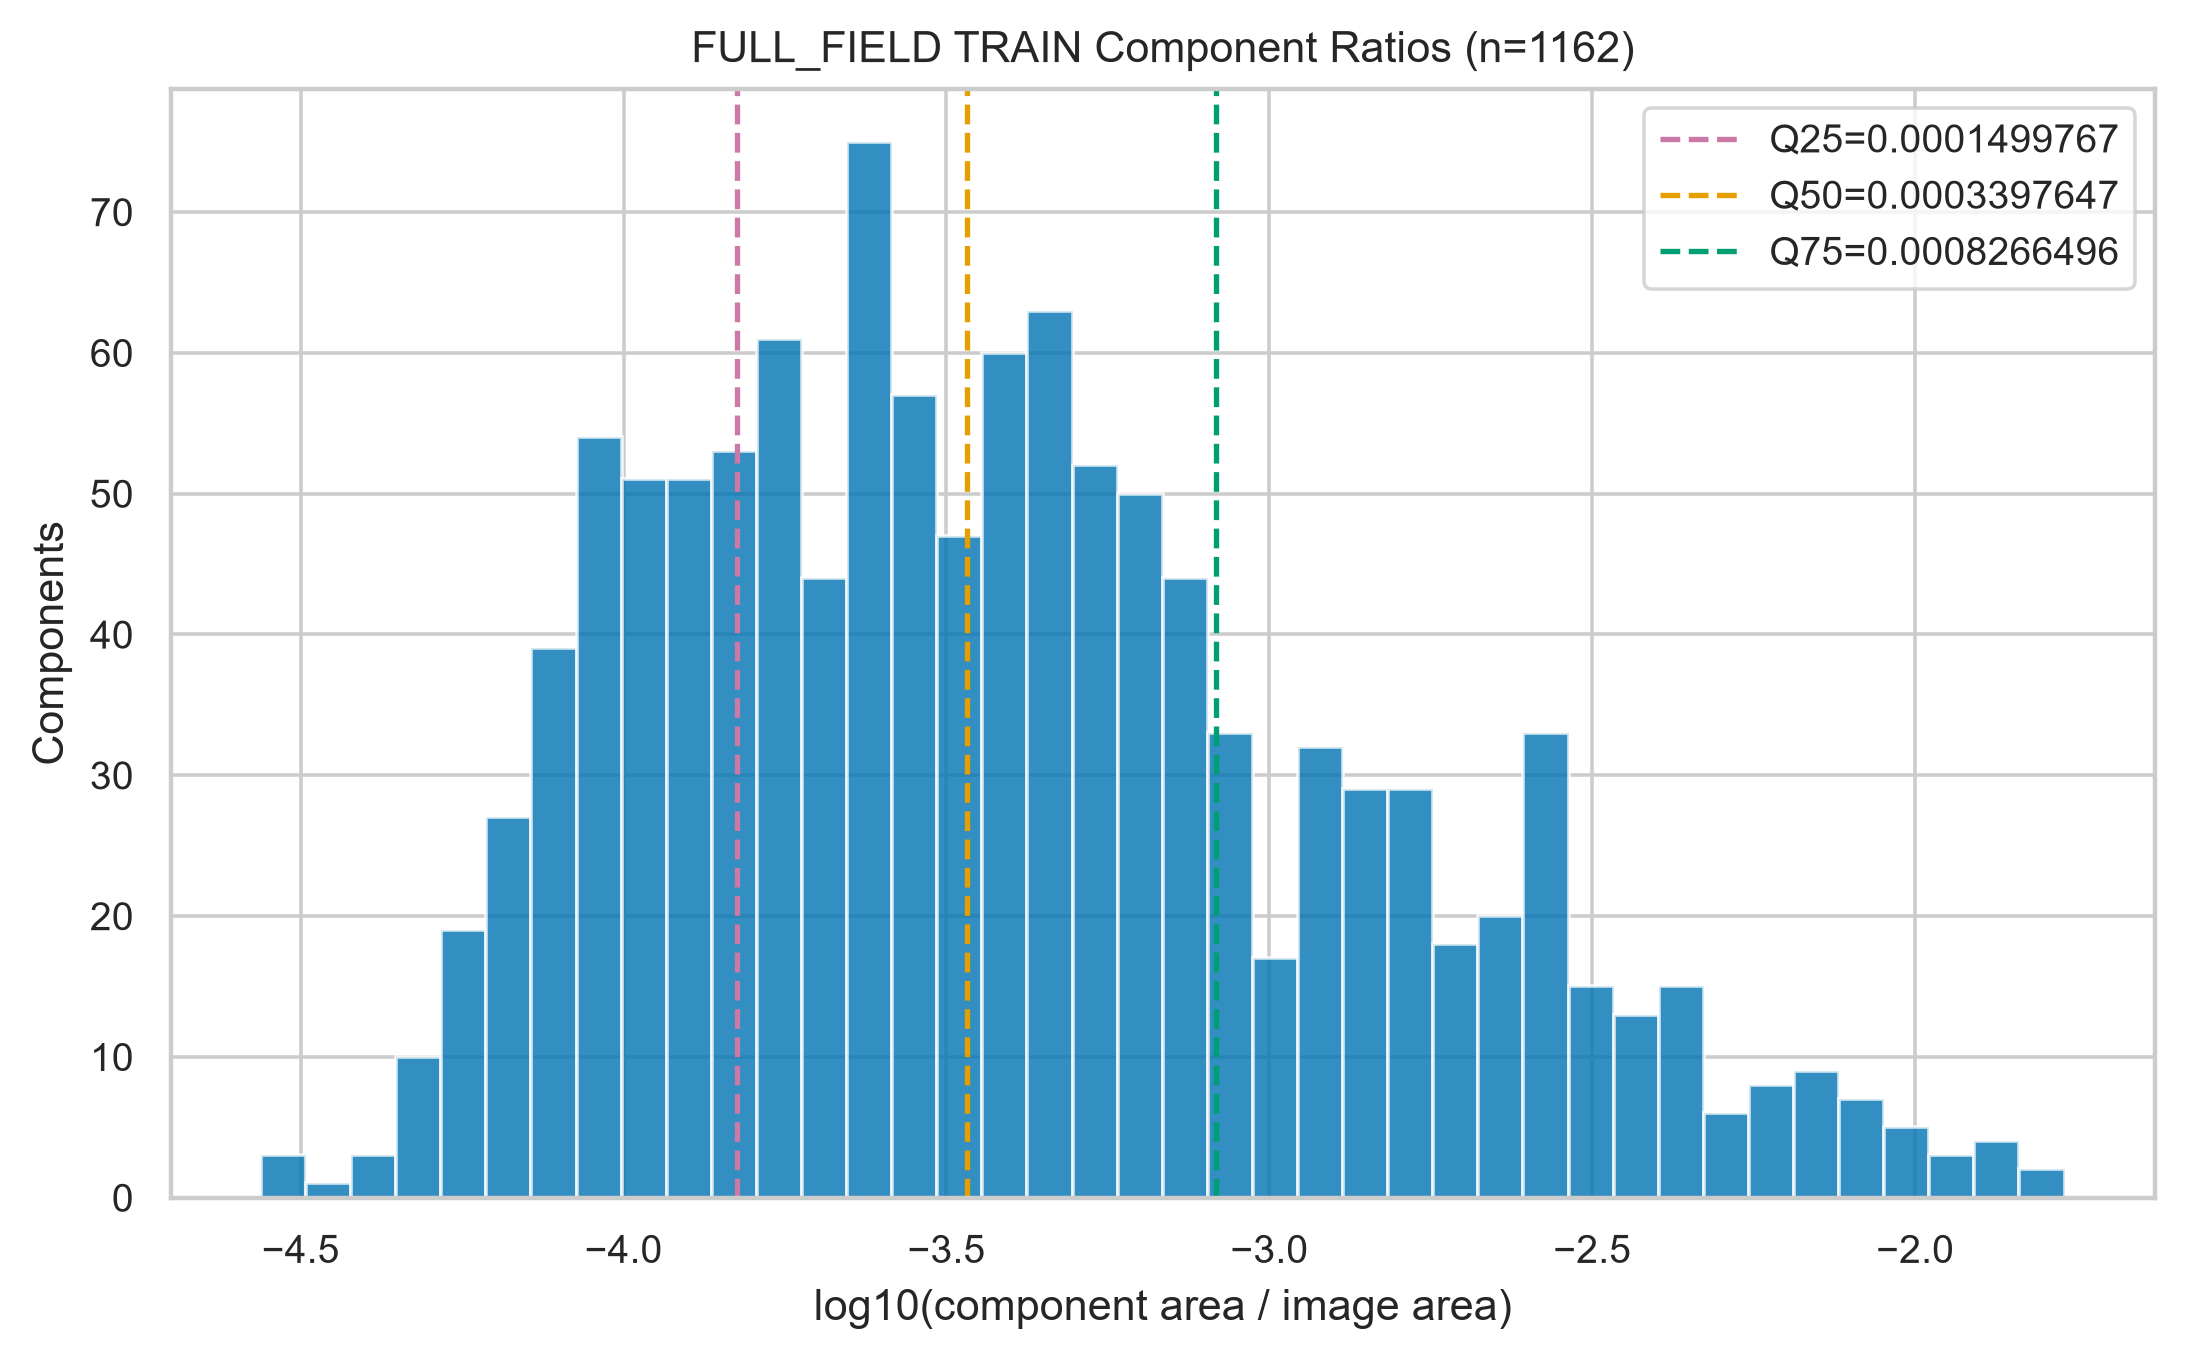

kub_object_size_by_category_v2


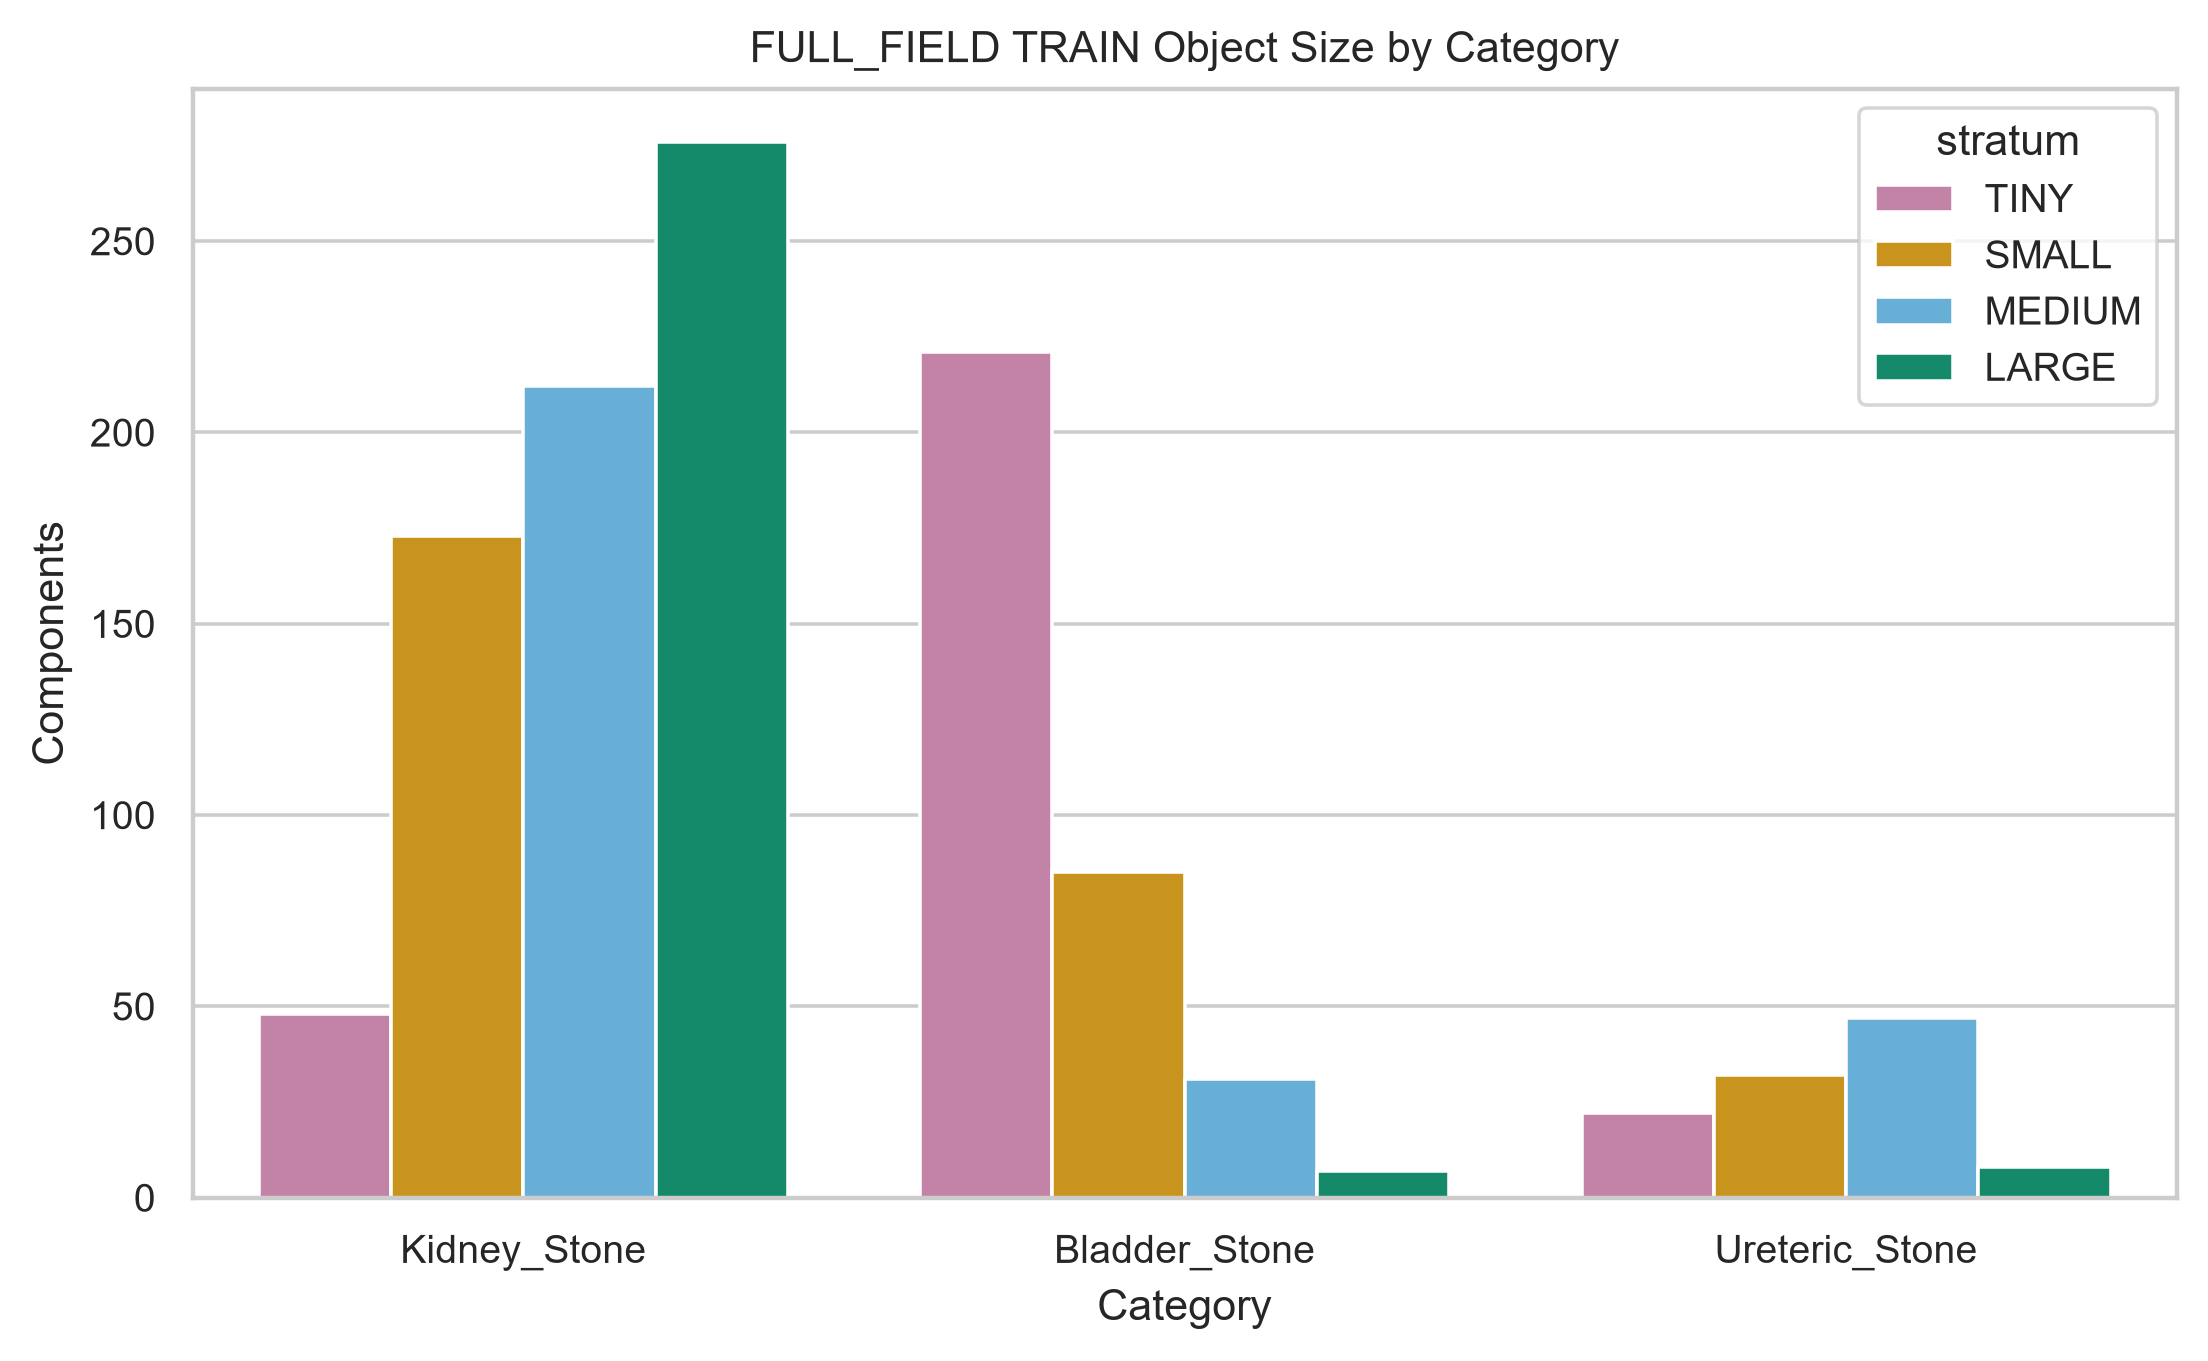

kub_object_size_train_val_v2


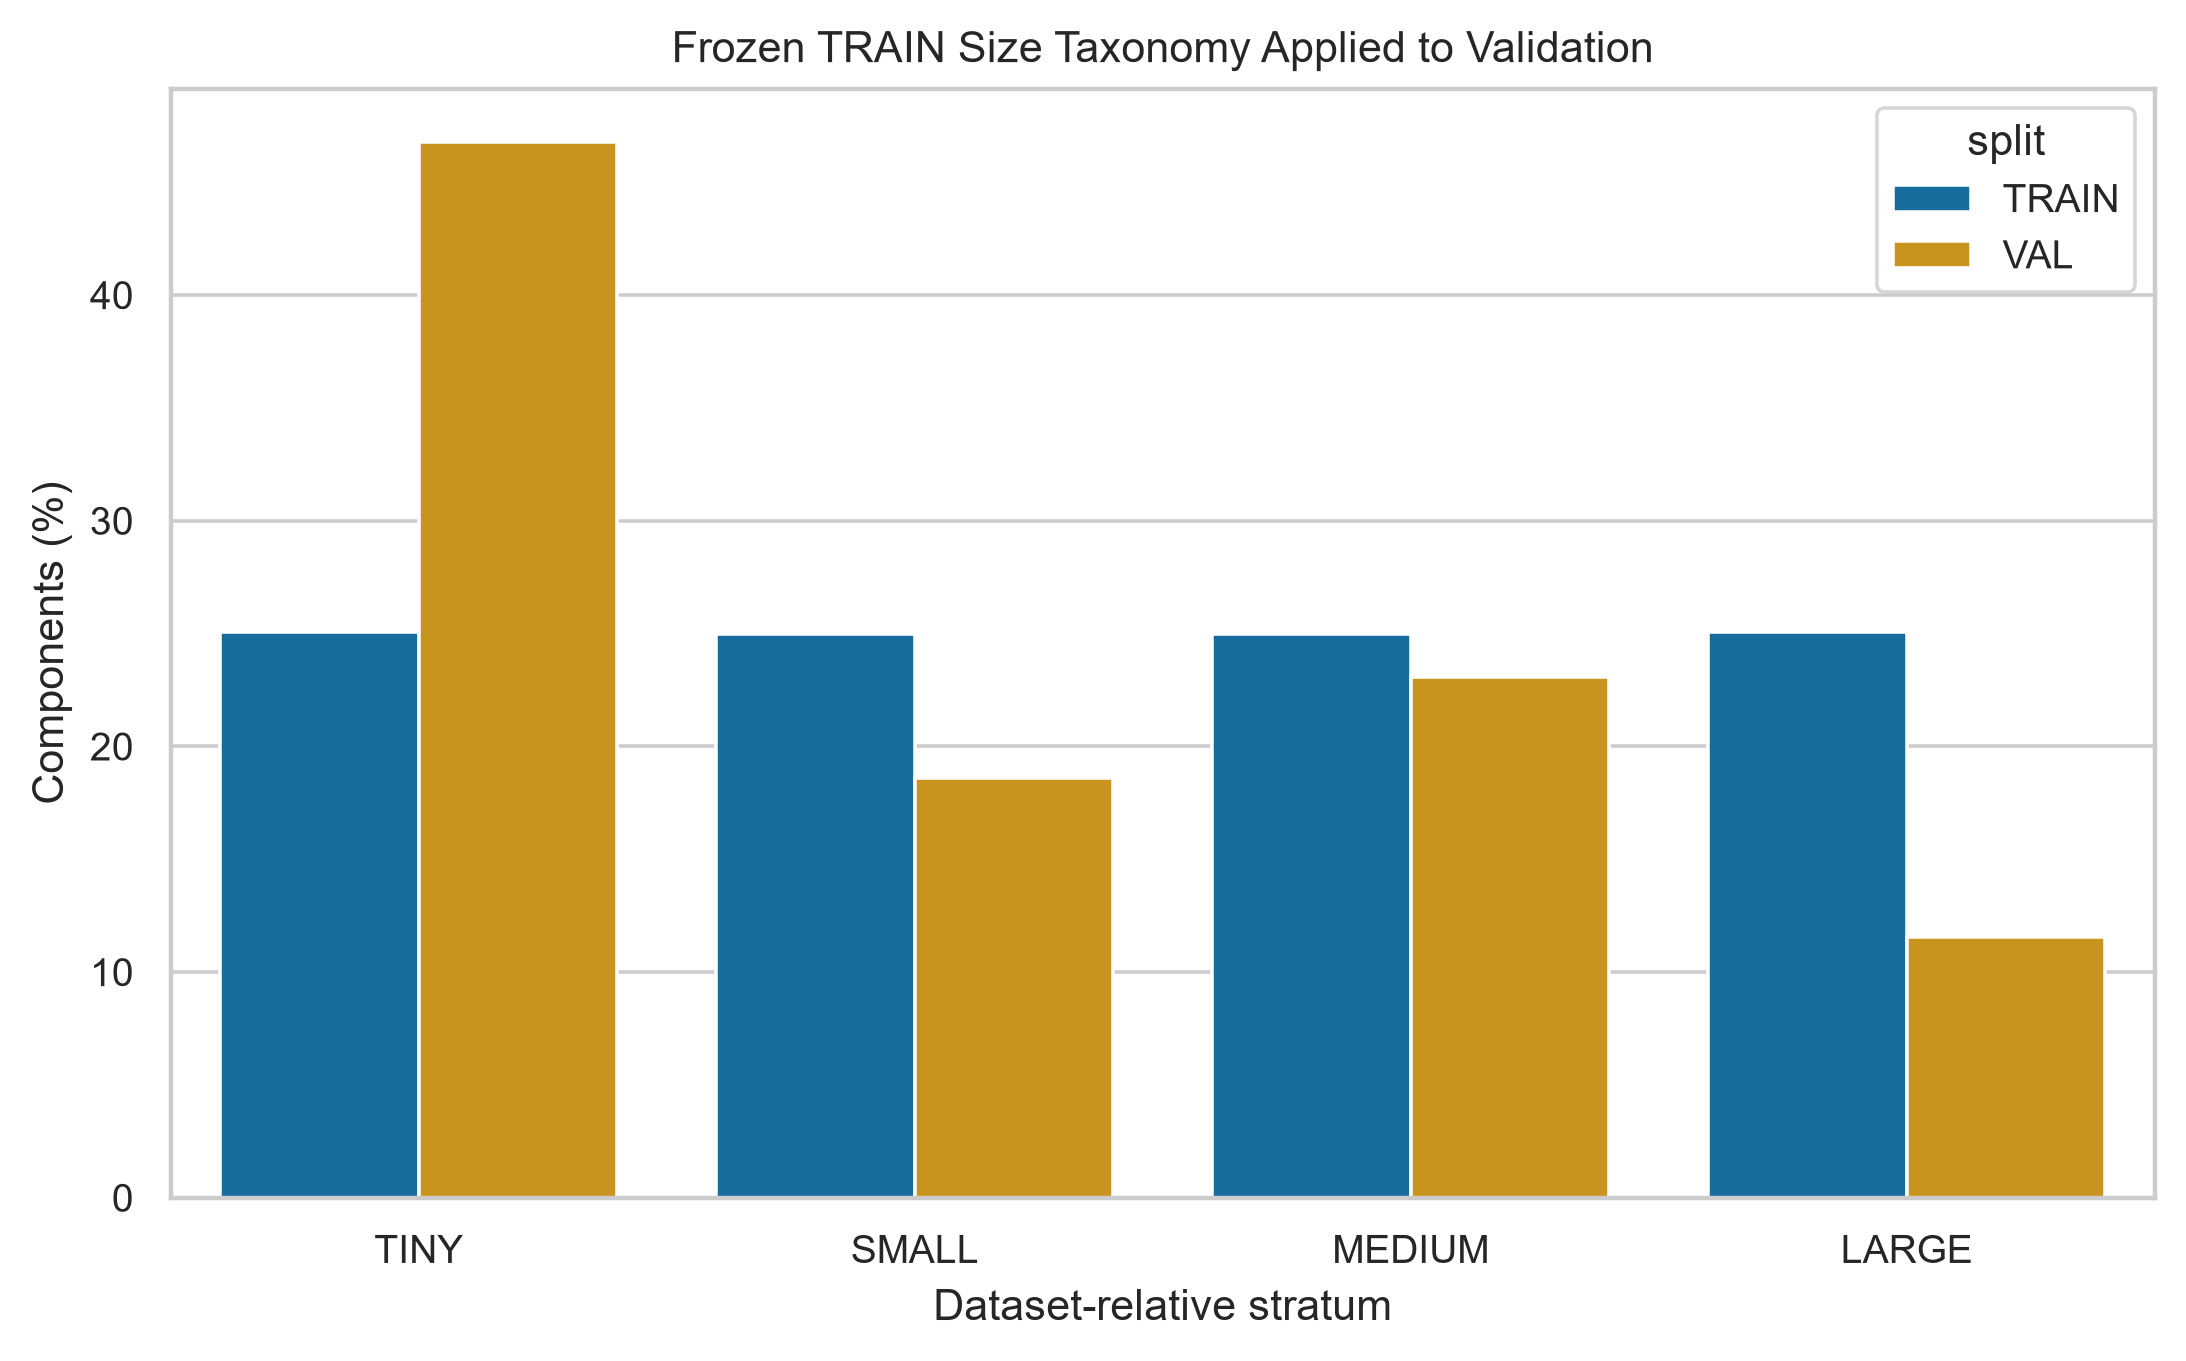

kub_roi_vs_fullfield_object_ratio_v2


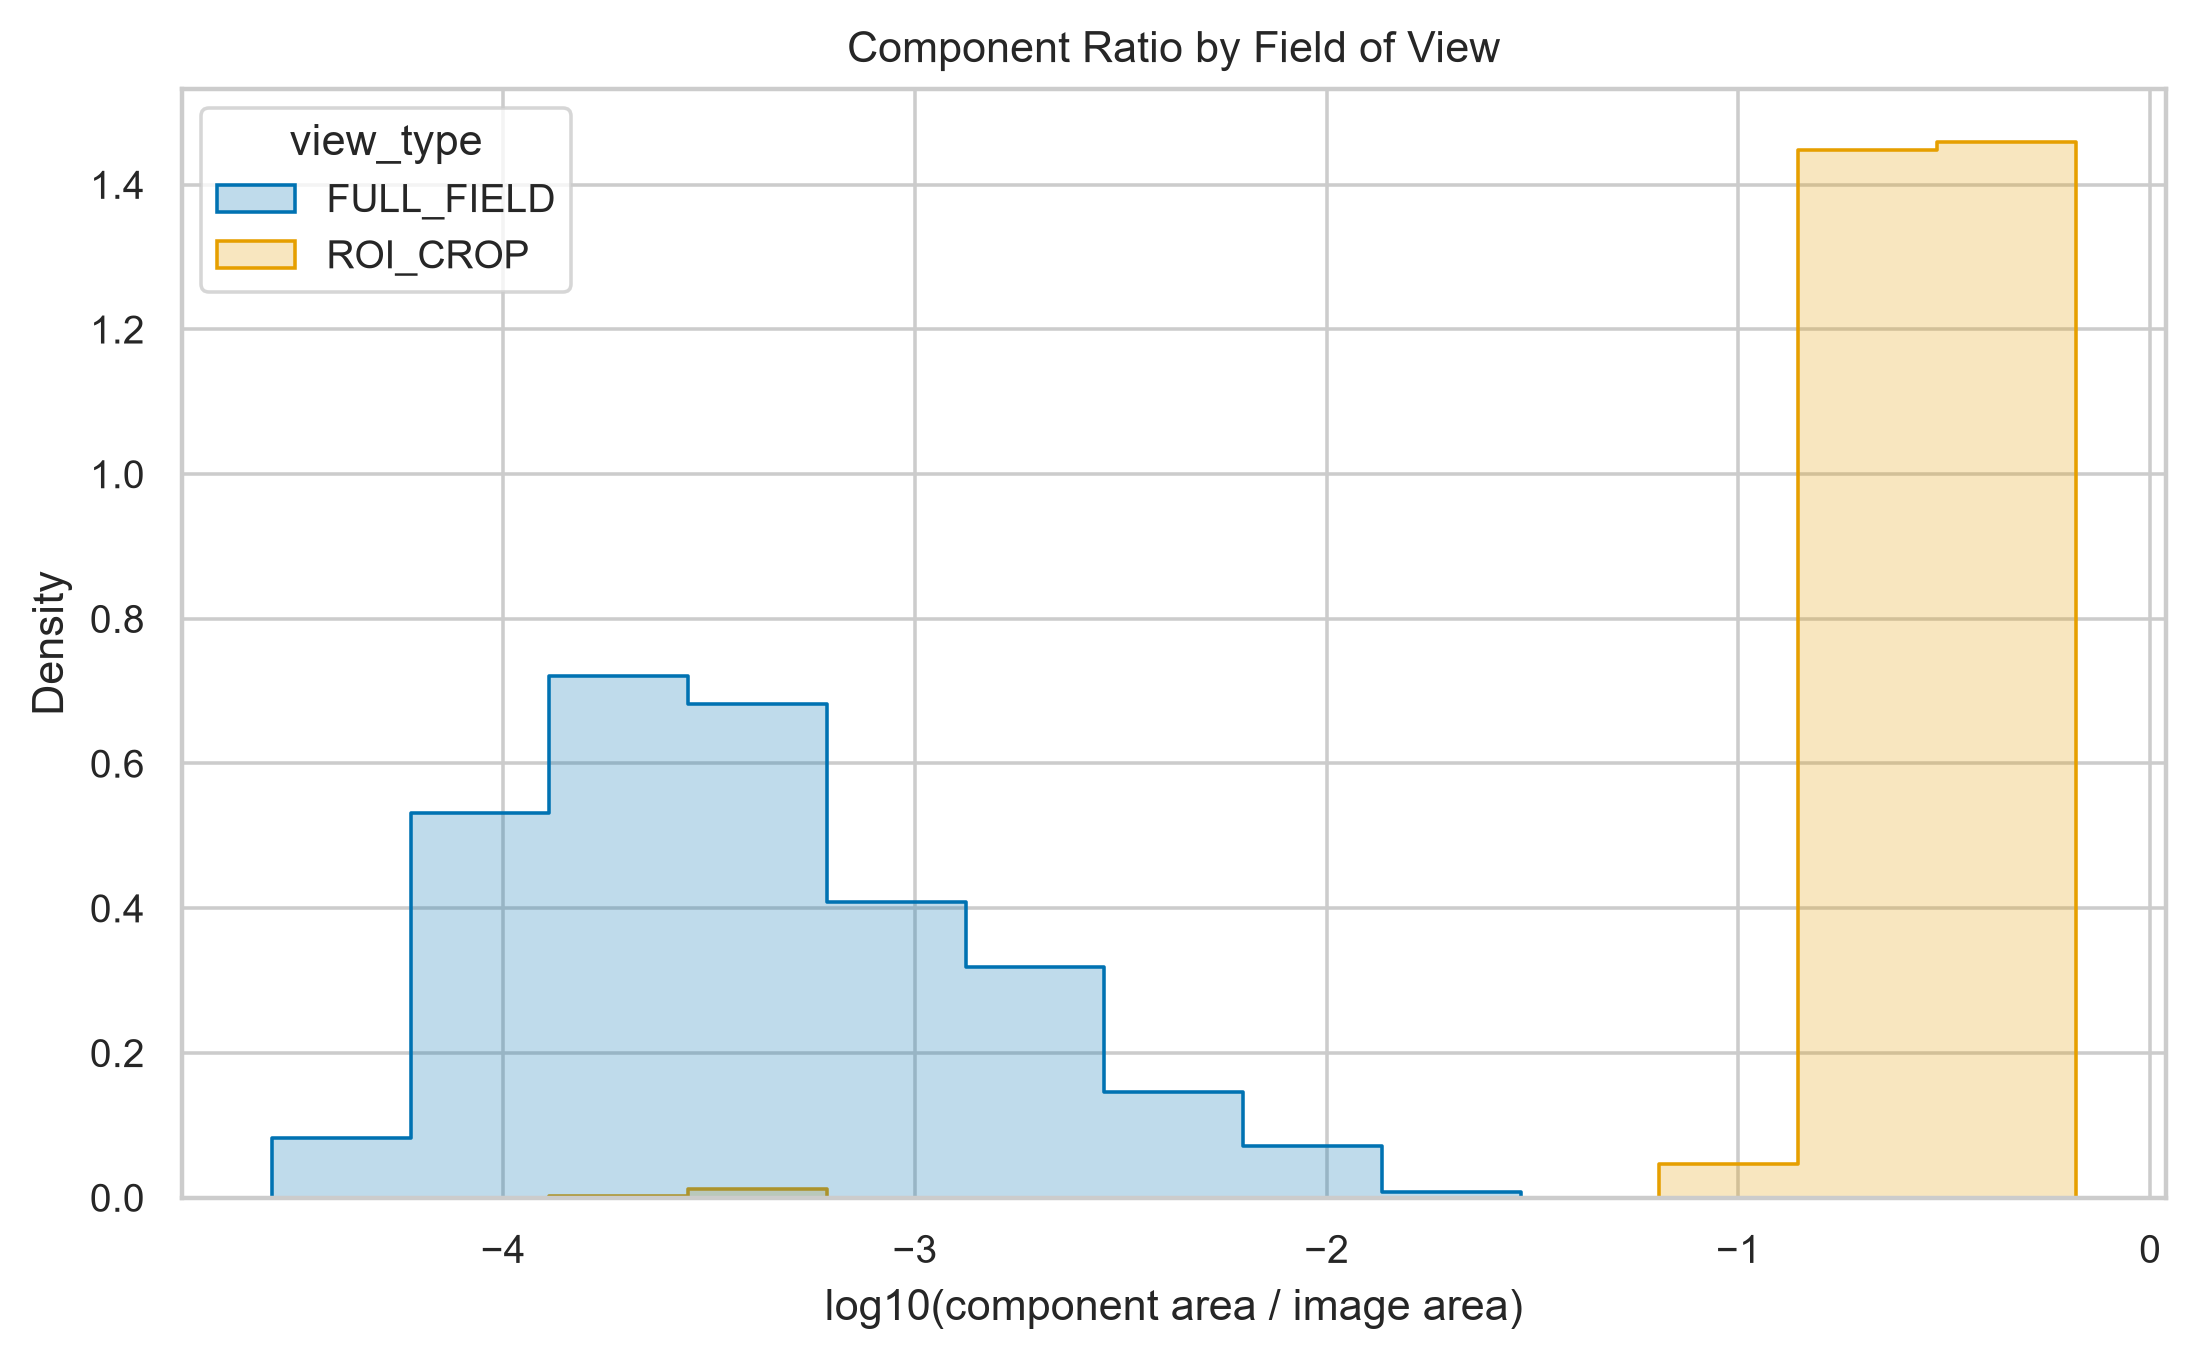

kub_multicomponent_size_combinations_v2


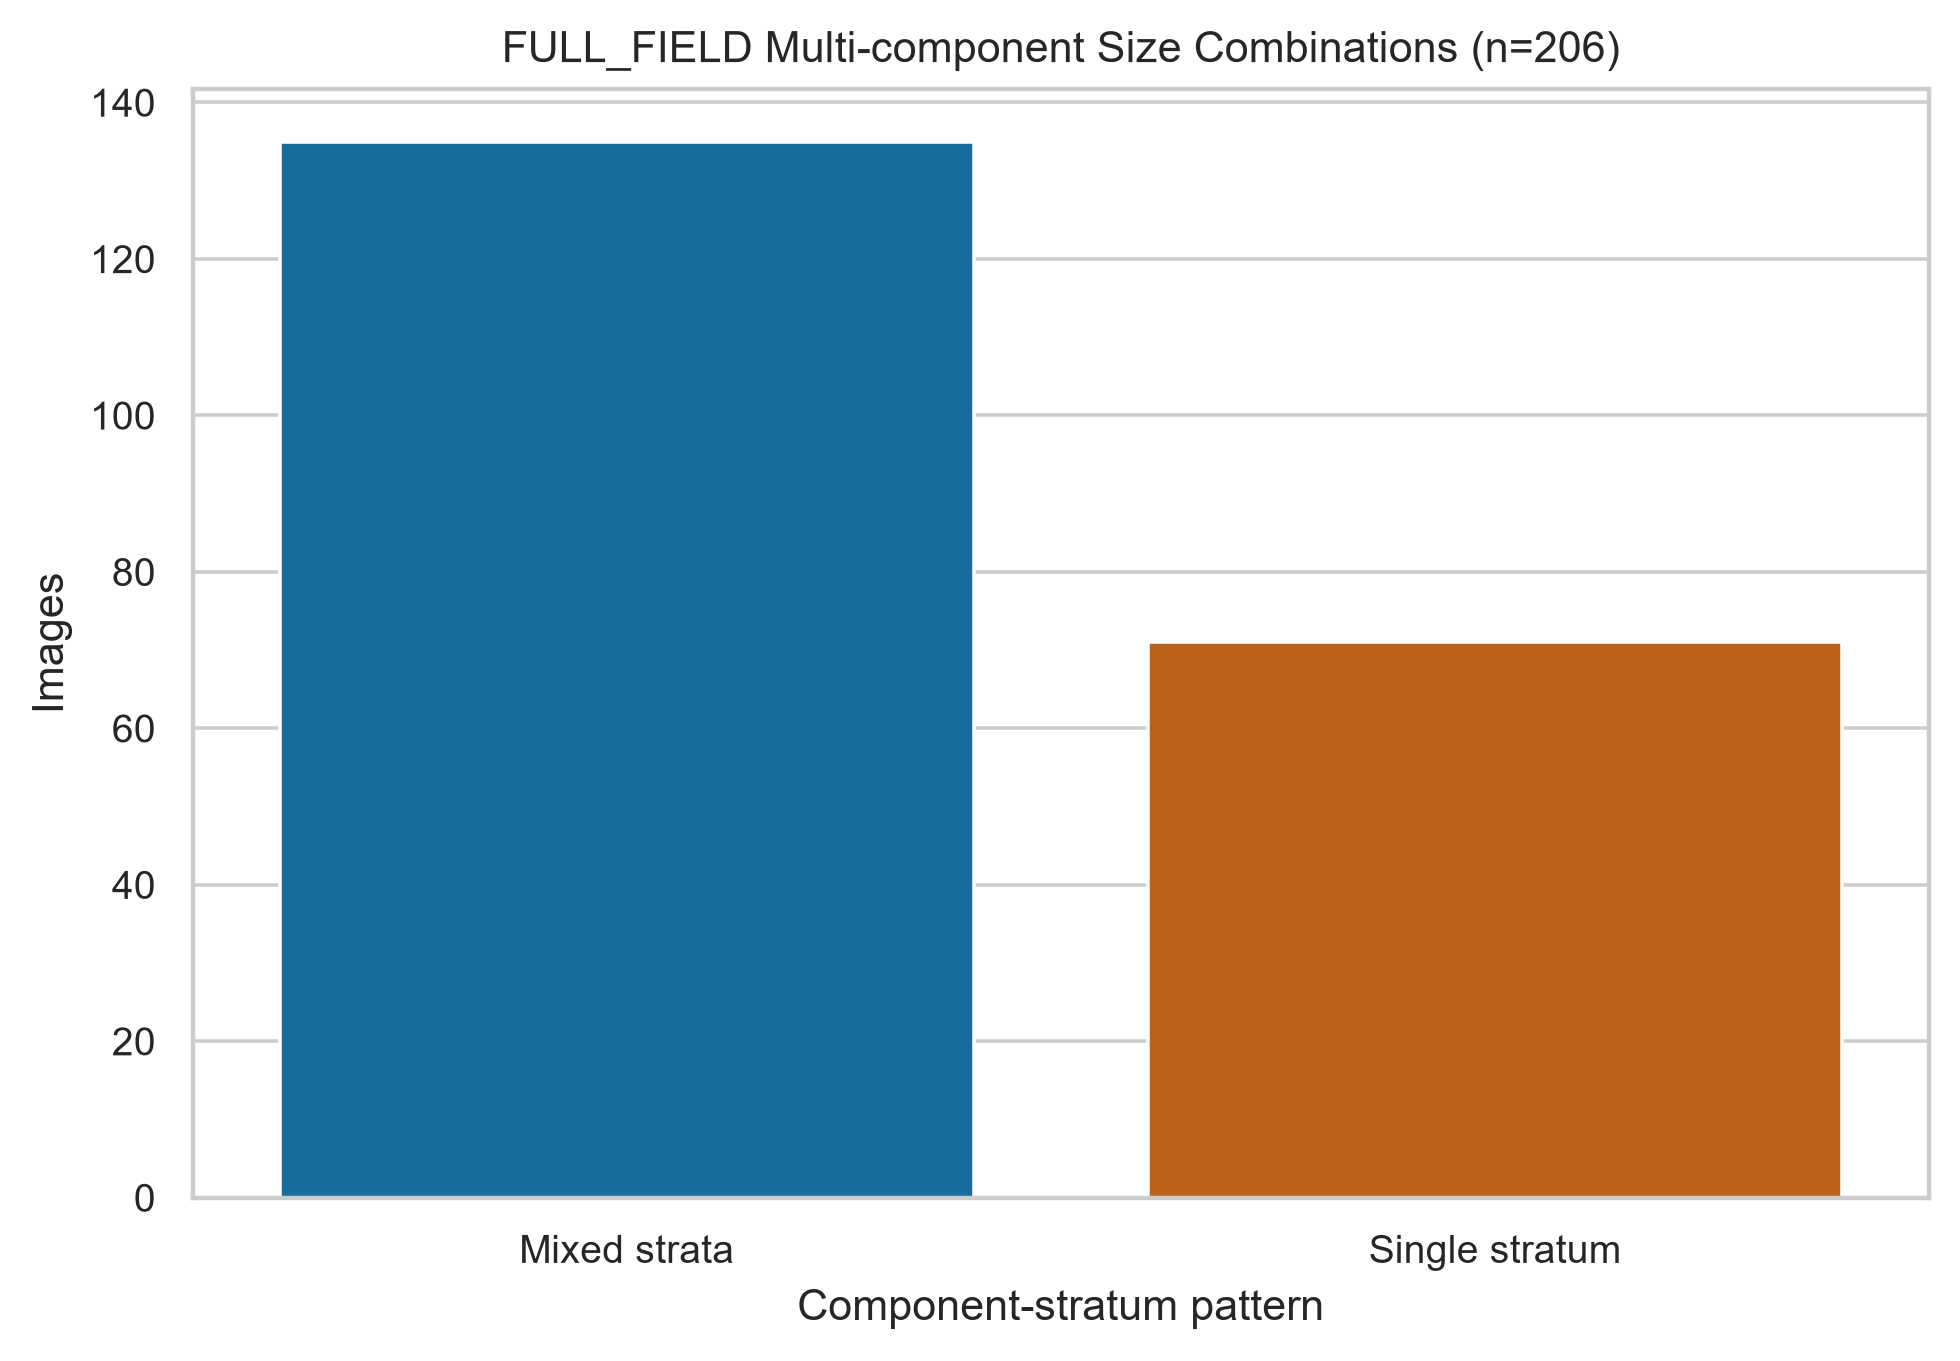

In [4]:
F=ROOT/'reports'/'figures'/'kub_object_size'
stems=['kub_fov_composition_v2','kub_fov_dimension_distribution_v2','kub_fullfield_object_size_thresholds_v2','kub_object_size_by_category_v2','kub_object_size_train_val_v2','kub_roi_vs_fullfield_object_ratio_v2','kub_multicomponent_size_combinations_v2']
for stem in stems:
    print(stem); display(Image(filename=str(F/f'{stem}.png')))

## Deterministic qualitative panels

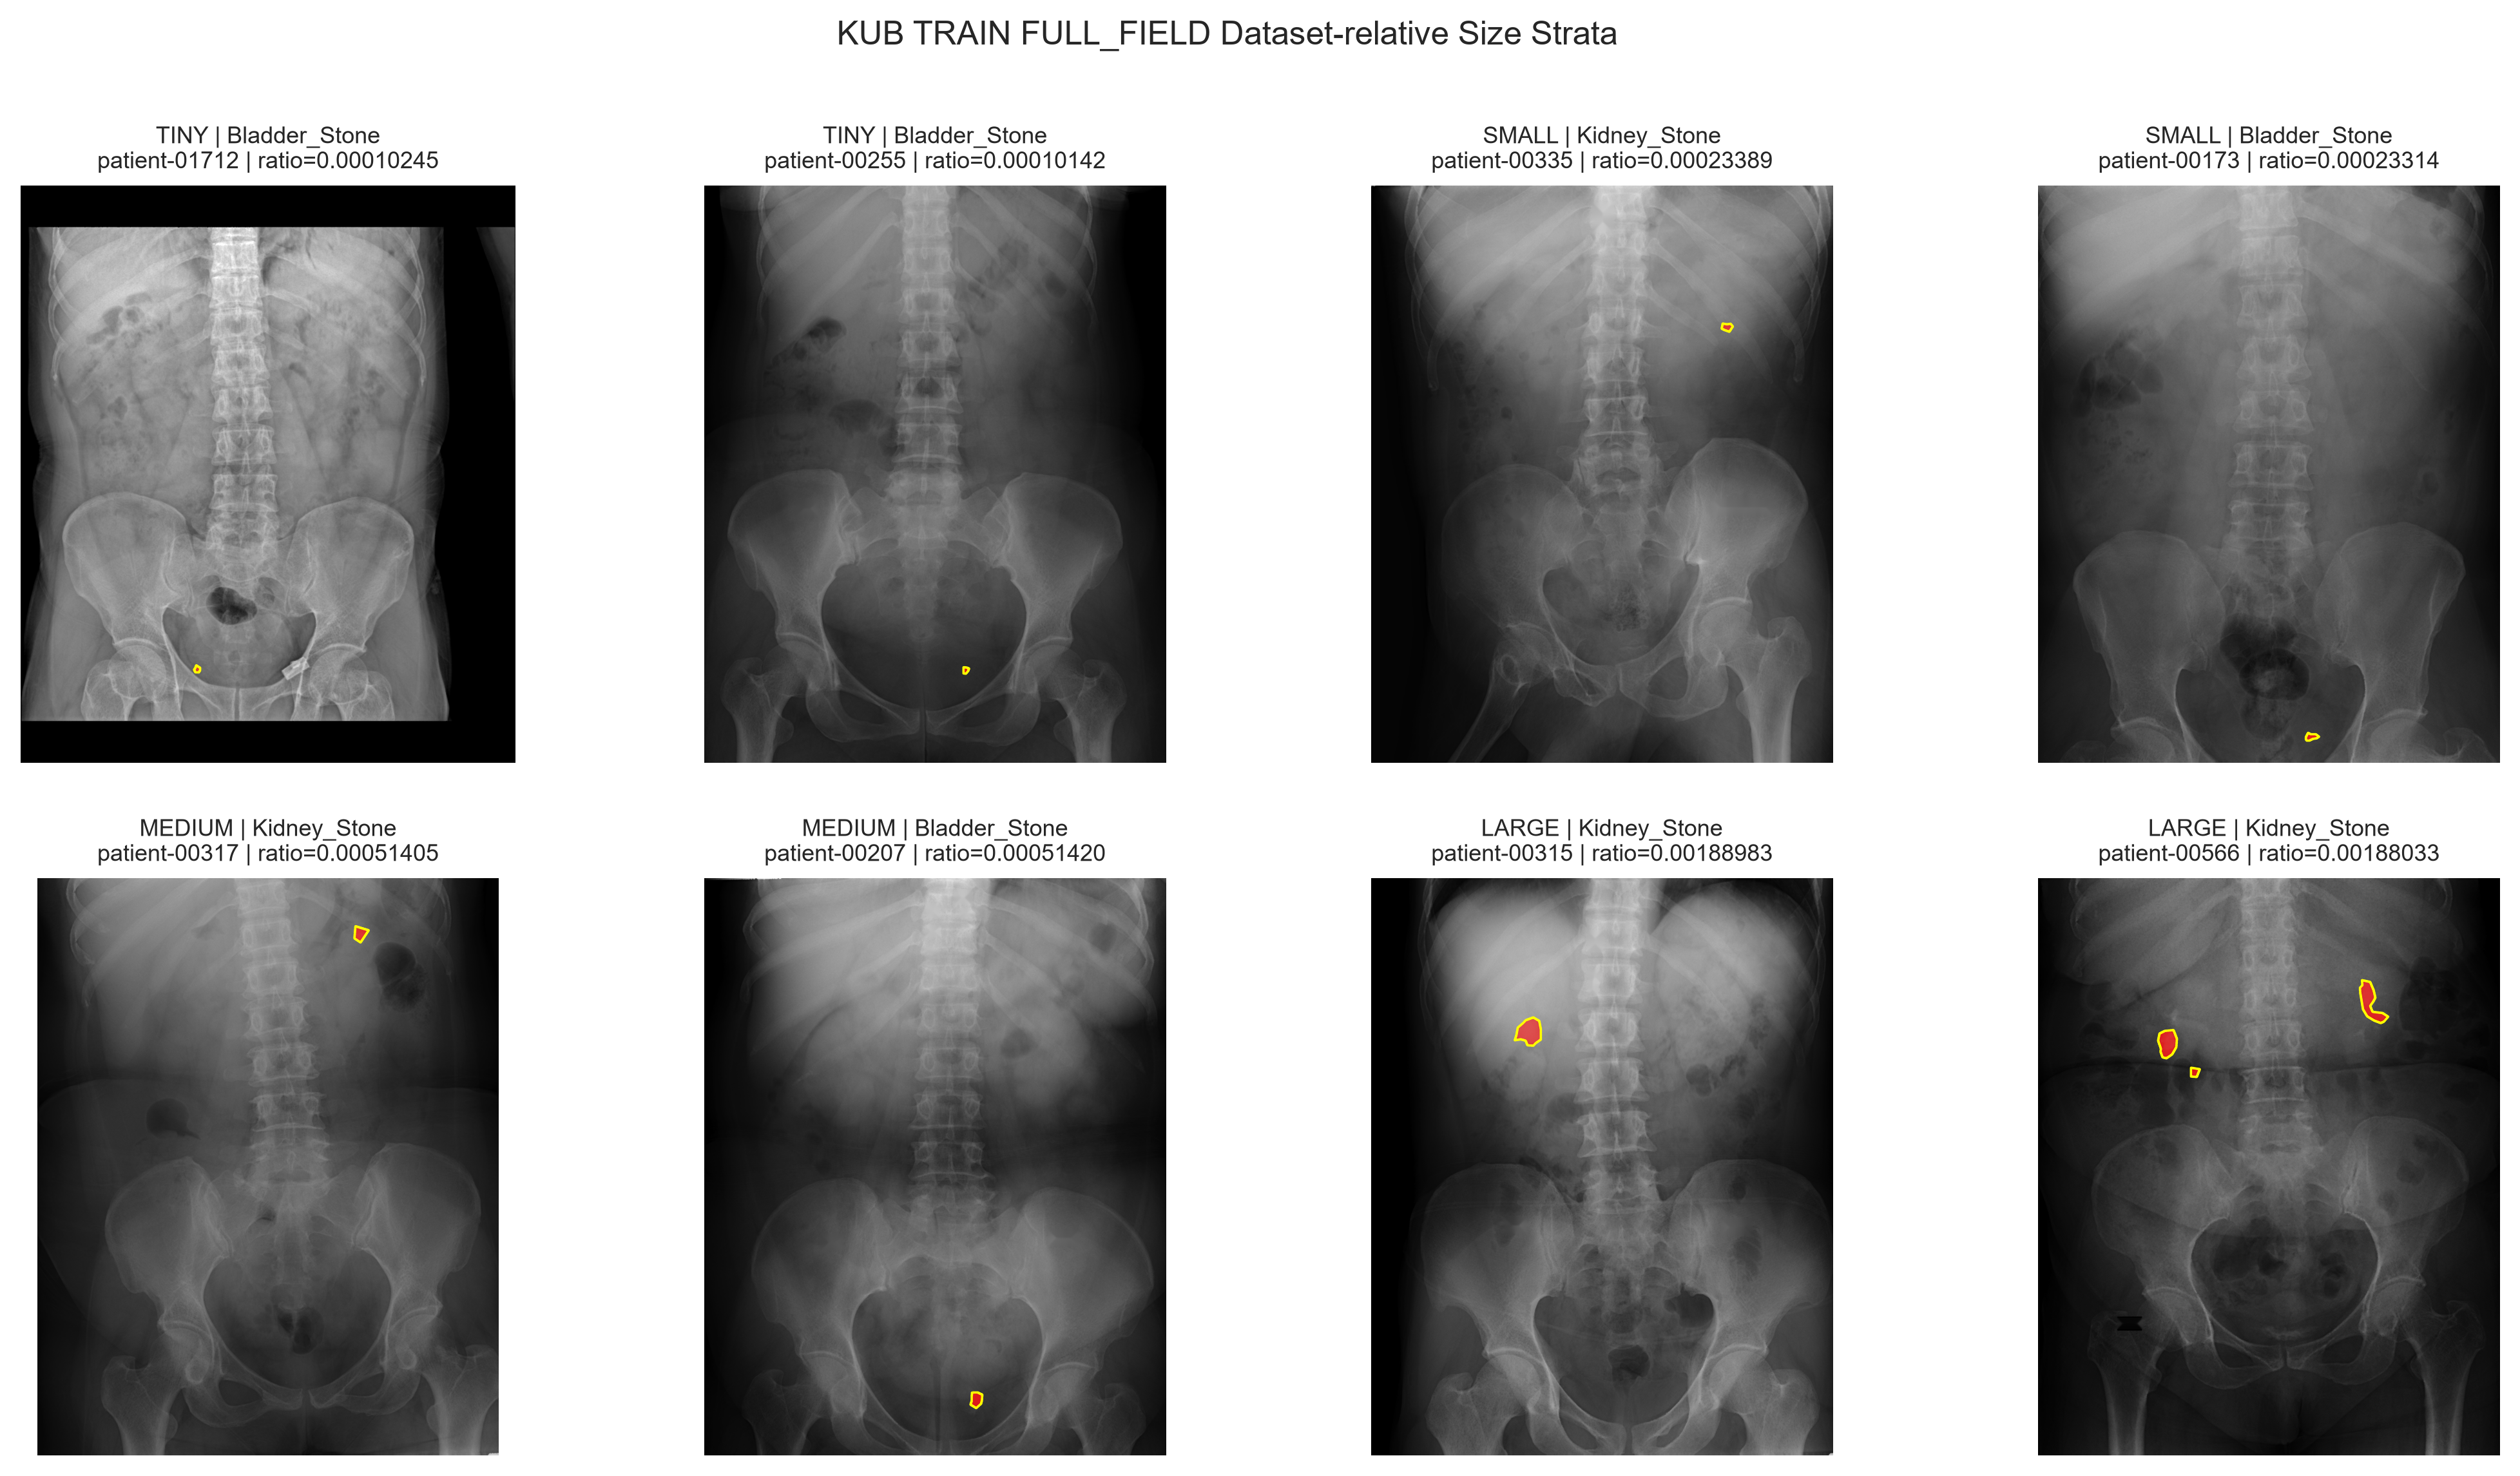

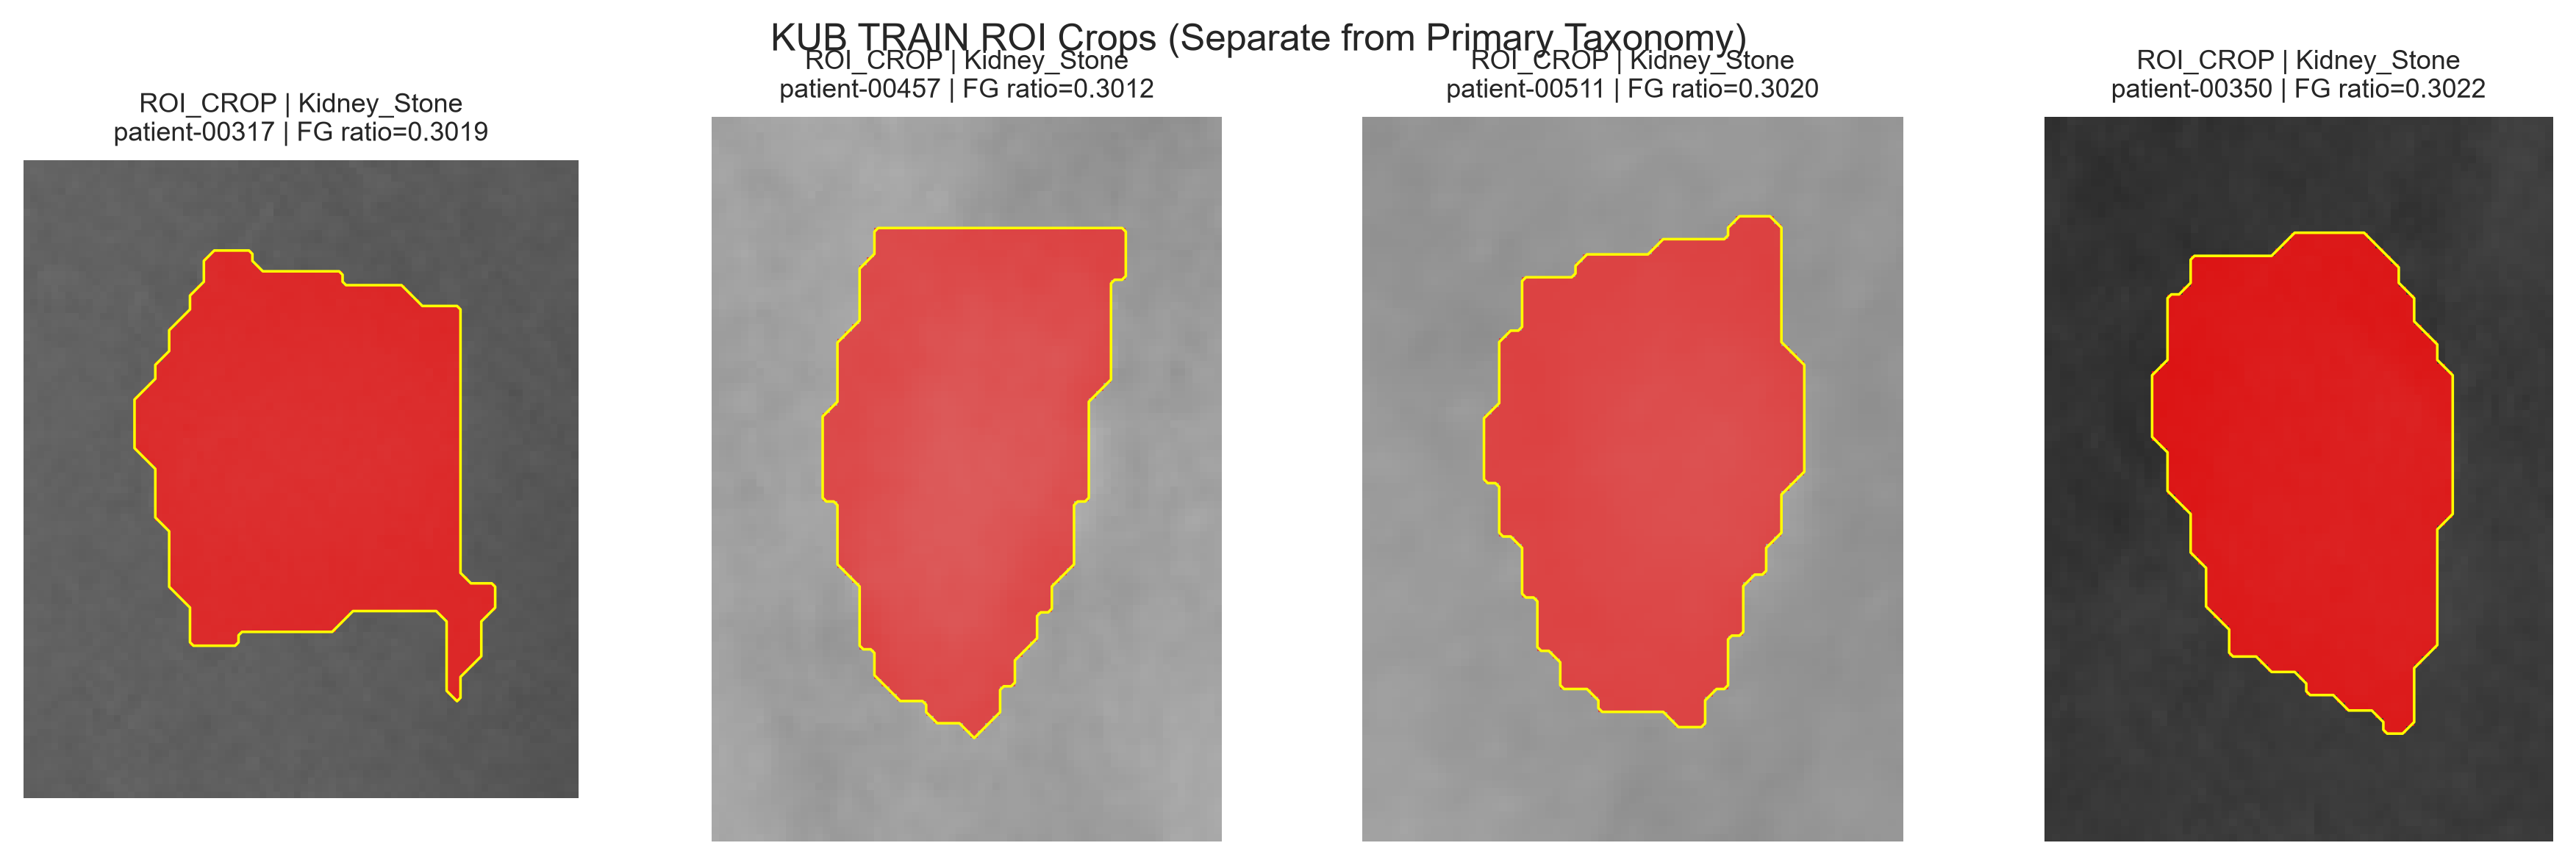

In [5]:
Q=ROOT/'reports'/'qualitative'/'kub_size_taxonomy'
display(Image(filename=str(Q/'kub_size_strata_examples_v2.png')))
display(Image(filename=str(Q/'kub_roi_examples_v2.png')))

## Measured interpretation and limitations
TRAIN has 771 FULL_FIELD samples (1,162 components) and 1,208 ROI_CROP samples (1,214 components); sample and component units are reported separately. Among 771 FULL_FIELD training images, 206 (26.72%) contained multiple connected components. Of these 206 images, 135 (65.53%) contained components spanning more than one dataset-relative size stratum; those 135 images are 17.51% of all FULL_FIELD images. Forty-four contained a TINY component plus a larger component. Component-level exposure shows 183 patients represented one stratum, 100 represented two, 30 represented three, and 3 represented all four; therefore 133 of 316 FULL_FIELD patients represented at least two strata. The earlier value 69 used variation in image-level dominant strata and did not implement the component-exposure definition. `kub_size_v1` remains unchanged and is estimated from TRAIN FULL_FIELD components only. All strata are dataset-relative, not clinical/mm grades. VAL uses frozen TRAIN thresholds. TEST morphology and external data remain unaccessed.